In [1]:
import os
import pandas as pd

from sqlalchemy import create_engine, text, URL
from langchain_core.tools import tool

# Read credentials from environment variables
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("POSTGRES_USER", "postgres"),
    password=os.getenv("POSTGRES_PASSWORD"),
    host="localhost",
    port=5432,
    database="ecommerce_analytics"
)

engine = create_engine(db_url)

# Test the connection
with engine.connect() as connection:
    print(connection.execute(text("SELECT 1")).scalar())

print("PostgreSQL connected successfully!")


1
PostgreSQL connected successfully!


In [2]:

# from previous notebook
def detect_anomalies(threshold=100, limit=10):
    query = text("""
        SELECT
            "InvoiceNo",
            "Description",
            "Quantity",
            "Revenue",
            CASE
                WHEN "Quantity" > :high_threshold THEN 'High Risk'
                WHEN "Quantity" > :threshold THEN 'Review'
                ELSE 'Normal'
            END AS anomaly_status
        FROM online_retail
        WHERE "Quantity" > :threshold
        ORDER BY "Quantity" DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={
                "threshold": threshold,
                "high_threshold": threshold * 10,
                "limit": limit
            }
        )

    return results

def get_monthly_revenue():
    query = text("""
        WITH monthly_sales AS (
            SELECT
                "Month",
                SUM("Revenue") AS monthly_revenue
            FROM online_retail
            GROUP BY "Month"
        ),
        monthly_comparison AS (
            SELECT
                "Month",
                monthly_revenue,
                LAG(monthly_revenue) OVER (
                    ORDER BY "Month"
                ) AS previous_revenue
            FROM monthly_sales
        )
        SELECT
            "Month",
            ROUND(monthly_revenue::numeric, 2) AS revenue,
            ROUND(previous_revenue::numeric, 2) AS previous_revenue,
            ROUND(
                (
                    (monthly_revenue - previous_revenue)
                    / NULLIF(previous_revenue, 0) * 100
                )::numeric,
                2
            ) AS growth_percentage
        FROM monthly_comparison
        ORDER BY "Month";
    """)

    with engine.connect() as connection:
        results = pd.read_sql(query, connection)

    return results

def get_top_products(limit=10):
    query = text("""
        SELECT
            "StockCode",
            "Description",
            SUM("Quantity") AS total_units_sold,
            ROUND(SUM("Revenue")::numeric, 2) AS total_revenue,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices
        FROM online_retail
        WHERE "Quantity" > 0
          AND "Revenue" > 0
          AND "Description" IS NOT NULL
        GROUP BY "StockCode", "Description"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={"limit": limit}
        )

    return results


In [3]:
# now converting functions to langchain tools
@tool
def anomaly_detection_tool(threshold:int = 100, limit:int = 10):
    """Find unusually high-quantity transactions.

    Use for questions about suspicious transactions or sales anomalies.
    Threshold sets the minimum quantity to flag.
    Limit sets the maximum quantity to flag.
    """
    res = detect_anomalies(threshold=threshold, limit=limit)
    return res.to_json(orient='records')

@tool
def monthly_revenue_tool() -> str:
    """
    Analyze monthly revenue and month over month growth.

    Use for questions about monthly sales sales, revenue trends, revenue increases, or revenue declines.
    """
    res = get_monthly_revenue()
    return res.to_json(orient='records')#records/columns/index

@tool
def top_products_tool(limit: int = 10)->str:
    """
    Find products ranked by total revenue.
    Use for questions about top products, product performance  or highest product revenue.
    """
    res = get_top_products(limit=limit)
    return res.to_json(orient='records')

In [4]:

# Test 1: Top 5 products
print("TOP PRODUCTS")
print(top_products_tool.invoke({"limit": 5}))

# Test 2: Monthly revenue
print("\nMONTHLY REVENUE")
print(monthly_revenue_tool.invoke({}))

# Test 3: Anomalies above quantity 500
print("\nANOMALIES")
print(anomaly_detection_tool.invoke({
    "threshold": 500,
    "limit": 5
}))


TOP PRODUCTS
[{"StockCode":"DOT","Description":"DOTCOM POSTAGE","total_units_sold":706.0,"total_revenue":206248.77,"total_invoices":706},{"StockCode":"22423","Description":"REGENCY CAKESTAND 3 TIER","total_units_sold":13879.0,"total_revenue":174484.74,"total_invoices":1988},{"StockCode":"23843","Description":"PAPER CRAFT , LITTLE BIRDIE","total_units_sold":80995.0,"total_revenue":168469.6,"total_invoices":1},{"StockCode":"85123A","Description":"WHITE HANGING HEART T-LIGHT HOLDER","total_units_sold":37599.0,"total_revenue":104340.29,"total_invoices":2189},{"StockCode":"47566","Description":"PARTY BUNTING","total_units_sold":18295.0,"total_revenue":99504.33,"total_invoices":1685}]

MONTHLY REVENUE
[{"Month":"2010-12","revenue":823746.14,"previous_revenue":null,"growth_percentage":null},{"Month":"2011-01","revenue":691364.5600000001,"previous_revenue":823746.14,"growth_percentage":-16.07},{"Month":"2011-02","revenue":523631.89,"previous_revenue":691364.5600000001,"growth_percentage":-24.2

In [5]:

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0
)

print("LLM initialized successfully!")

LLM initialized successfully!


In [6]:
tools = [
    anomaly_detection_tool,
    monthly_revenue_tool,
    top_products_tool
]

print("Registered tools:")
for t in tools:
    print("-", t.name)
llm_with_tools = llm.bind_tools(tools)

print("LLM connected to analytics tools!")

Registered tools:
- anomaly_detection_tool
- monthly_revenue_tool
- top_products_tool
LLM connected to analytics tools!


In [7]:
from langchain_core.messages import HumanMessage, ToolMessage

question = "Which are the top 69 products by revenue?"
response = llm_with_tools.invoke([
    HumanMessage(content=question)
])
tool_results = []

for tool_call in response.tool_calls:
    selected_tool = next(
        t for t in tools
        if t.name == tool_call["name"]
    )
    result = selected_tool.invoke(tool_call["args"])
    tool_results.append(
        ToolMessage(
            content=str(result),
            tool_call_id=tool_call["id"]
        )
    )

print("TOOL RESULTS:")
for result in tool_results:
    print(result.content)

TOOL RESULTS:
[{"StockCode":"DOT","Description":"DOTCOM POSTAGE","total_units_sold":706.0,"total_revenue":206248.77,"total_invoices":706},{"StockCode":"22423","Description":"REGENCY CAKESTAND 3 TIER","total_units_sold":13879.0,"total_revenue":174484.74,"total_invoices":1988},{"StockCode":"23843","Description":"PAPER CRAFT , LITTLE BIRDIE","total_units_sold":80995.0,"total_revenue":168469.6,"total_invoices":1},{"StockCode":"85123A","Description":"WHITE HANGING HEART T-LIGHT HOLDER","total_units_sold":37599.0,"total_revenue":104340.29,"total_invoices":2189},{"StockCode":"47566","Description":"PARTY BUNTING","total_units_sold":18295.0,"total_revenue":99504.33,"total_invoices":1685},{"StockCode":"85099B","Description":"JUMBO BAG RED RETROSPOT","total_units_sold":48474.0,"total_revenue":94340.05,"total_invoices":2089},{"StockCode":"23166","Description":"MEDIUM CERAMIC TOP STORAGE JAR","total_units_sold":78033.0,"total_revenue":81700.92,"total_invoices":247},{"StockCode":"M","Description":"M

In [8]:
from langchain_core.messages import AIMessage

final_response = llm.invoke([
    HumanMessage(content=question),
    response,
    *tool_results
])

print(final_response.content)

Here are the top 69 products by revenue:

1. DOTCOM POSTAGE - $206,248.77
2. REGENCY CAKESTAND 3 TIER - $174,484.74
3. PAPER CRAFT , LITTLE BIRDIE - $168,469.60
4. WHITE HANGING HEART T-LIGHT HOLDER - $104,340.29
5. PARTY BUNTING - $99,504.33
6. JUMBO BAG RED RETROSPOT - $94,340.05
7. MEDIUM CERAMIC TOP STORAGE JAR - $81,700.92
8. Manual - $78,110.27
9. POSTAGE - $78,101.88
10. RABBIT NIGHT LIGHT - $66,964.99
11. PAPER CHAIN KIT 50'S CHRISTMAS - $64,952.29
12. ASSORTED COLOUR BIRD ORNAMENT - $59,094.93
13. CHILLI LIGHTS - $54,117.76
14. SPOTTY BUNTING - $42,548.13
15. JUMBO BAG PINK POLKADOT - $42,436.24
16. BLACK RECORD COVER FRAME - $40,652.13
17. PICNIC BASKET WICKER 60 PIECES - $39,619.50
18. DOORMAT KEEP CALM AND COME IN - $38,166.64
19. SET OF 3 CAKE TINS PANTRY DESIGN - $38,158.39
20. JAM MAKING SET WITH JARS - $37,128.88
21. WOOD BLACK BOARD ANT WHITE FINISH - $36,030.22
22. LUNCH BAG RED RETROSPOT - $35,752.01
23. POPCORN HOLDER - $34,298.87
24. VICTORIAN GLASS HANGING T-LIGHT

In [9]:
from langchain_core.messages import HumanMessage, ToolMessage

def run_agent(question):

    messages = [HumanMessage(content=question)]

    # First LLM call
    response = llm_with_tools.invoke(messages)

    while response.tool_calls:

        # Add AI response to conversation
        messages.append(response)

        # Execute selected tools
        for tool_call in response.tool_calls:

            selected_tool = next(
                t for t in tools
                if t.name == tool_call["name"]
            )

            result = selected_tool.invoke(tool_call["args"])

            messages.append(
                ToolMessage(
                    content=str(result),
                    tool_call_id=tool_call["id"]
                )
            )

        # Ask LLM to process tool results
        response = llm_with_tools.invoke(messages)

    return response.content

In [10]:
ans = run_agent(
    "Find transactions with quantities above 100. Return 100 records."
)

print(ans)


I found 100 transactions with quantities above 100. Here are some examples:

1. InvoiceNo: 581483, Description: PAPER CRAFT , LITTLE BIRDIE, Quantity: 80995, Revenue: 168469.6
2. InvoiceNo: 541431, Description: MEDIUM CERAMIC TOP STORAGE JAR, Quantity: 74215, Revenue: 77183.6
3. InvoiceNo: 573008, Description: WORLD WAR 2 GLIDERS ASSTD DESIGNS, Quantity: 4800, Revenue: 1008.0
4. InvoiceNo: 554868, Description: SMALL POPCORN HOLDER, Quantity: 4300, Revenue: 3096.0
5. InvoiceNo: 544612, Description: EMPIRE DESIGN ROSETTE, Quantity: 3906, Revenue: 3202.92

If you want details on more transactions or specific information, please let me know!


In [11]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-6-luna",
    temperature=0,
    reasoning_effort="none"
)

print("GPT-6 Luna initialized successfully!")

GPT-6 Luna initialized successfully!


In [12]:
tools = [
    anomaly_detection_tool,
    monthly_revenue_tool,
    top_products_tool
]

llm_with_tools = llm.bind_tools(tools)


In [13]:
from langchain_core.messages import HumanMessage

response = llm_with_tools.invoke([
    HumanMessage(
        content="Find the top 5 products by revenue."
    )
])

print(response.tool_calls)

[{'name': 'top_products_tool', 'args': {'limit': 5}, 'id': 'call_64yDciL1WLEHySZOEgHddL5Y', 'type': 'tool_call'}]


In [14]:
ans = run_agent(
    "Analyze monthly revenue and identify the month with the highest revenue."
)

print(ans)

The highest monthly revenue was in **November 2011**, at **1,509,496.33**. Revenue rose **30.69%** from October, then fell **57.68%** in December.


In [15]:
%pip install -U langgraph

Note: you may need to restart the kernel to use updated packages.


In [16]:
import langgraph

In [17]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
def chatbot(state: MessagesState): #messageState receives current conversation state
    response = llm_with_tools.invoke(state["messages"])

    return {
        "messages": [response]
    }
'''
Component	Purpose
StateGraph	Creates the agent's workflow graph
MessagesState	Stores the conversation messages
START	Entry point of the graph
END	Marks the end of the workflow
ToolNode	Executes tools selected by the LLM
tools_condition	Decides whether to execute tools or finish

'''

"\nComponent\tPurpose\nStateGraph\tCreates the agent's workflow graph\nMessagesState\tStores the conversation messages\nSTART\tEntry point of the graph\nEND\tMarks the end of the workflow\nToolNode\tExecutes tools selected by the LLM\ntools_condition\tDecides whether to execute tools or finish\n\n"

In [18]:
tool_node = ToolNode(tools)

In [19]:

graph_builder = StateGraph(MessagesState)


graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "chatbot")

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition
)

graph_builder.add_edge("tools", "chatbot")

agent = graph_builder.compile()


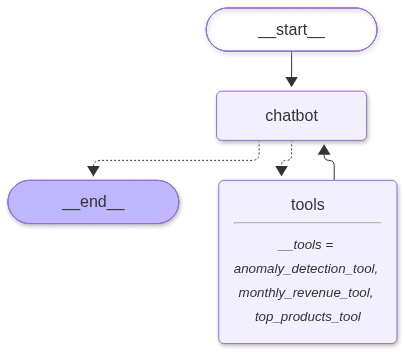

In [20]:
from IPython.display import Image, display

display(
    Image(agent.get_graph().draw_mermaid_png())
)

In [21]:
from langchain_core.messages import HumanMessage

response = agent.invoke({
    "messages": [
        HumanMessage(
            content="What are the top 7 products by revenue?"
        )
    ]
})

print(response["messages"][-1].content)

Top 7 products by revenue:

| Rank | Product | Stock code | Revenue |
|---:|---|---|---:|
| 1 | DOTCOM POSTAGE | DOT | £206,248.77 |
| 2 | REGENCY CAKESTAND 3 TIER | 22423 | £174,484.74 |
| 3 | PAPER CRAFT, LITTLE BIRDIE | 23843 | £168,469.60 |
| 4 | WHITE HANGING HEART T-LIGHT HOLDER | 85123A | £104,340.29 |
| 5 | PARTY BUNTING | 47566 | £99,504.33 |
| 6 | JUMBO BAG RED RETROSPOT | 85099B | £94,340.05 |
| 7 | MEDIUM CERAMIC TOP STORAGE JAR | 23166 | £81,700.92 |


In [22]:
response = agent.invoke({
    "messages": [
        HumanMessage(
            content="Analyze monthly revenue and identify the top 5 highest months with the highest revenue."
        )
    ]
})

print(response["messages"][-1].content)

### Top 5 months by revenue

| Rank | Month | Revenue |
|---:|---|---:|
| 1 | November 2011 | 1,509,496.33 |
| 2 | October 2011 | 1,154,979.30 |
| 3 | September 2011 | 1,058,590.17 |
| 4 | December 2010 | 823,746.14 |
| 5 | May 2011 | 770,536.02 |

November 2011 was the highest-revenue month. Revenue rose for three consecutive months from September through November, then fell sharply in December 2011.


In [23]:
from langchain_core.messages import HumanMessage

response = agent.invoke({
    "messages": [
        HumanMessage(
            content="What are the top 5 products by revenue?"
        )
    ]
})

print(response["messages"][-1].content)

Top 5 products by revenue:

| Rank | Product | Revenue |
|---:|---|---:|
| 1 | DOTCOM POSTAGE | £206,248.77 |
| 2 | REGENCY CAKESTAND 3 TIER | £174,484.74 |
| 3 | PAPER CRAFT, LITTLE BIRDIE | £168,469.60 |
| 4 | WHITE HANGING HEART T-LIGHT HOLDER | £104,340.29 |
| 5 | PARTY BUNTING | £99,504.33 |


In [24]:
response = agent.invoke({
    "messages": [
        HumanMessage(
            content="Analyze monthly revenue and identify the month with the highest revenue."
        )
    ]
})

print(response["messages"][-1].content)

Revenue peaked in **November 2011**, at **1,509,496.33**. It rose **30.69%** from October, then fell **57.68%** in December.


In [25]:
response = agent.invoke({
    "messages": [
        HumanMessage(
            content="Find 20 transactions with quantities above 500."
        )
    ]
})

print(response["messages"][-1].content)

Here are 20 transactions with quantities above 500, ordered from highest to lowest:

| Invoice | Product | Quantity | Revenue | Status |
|---|---|---:|---:|---|
| 581483 | PAPER CRAFT, LITTLE BIRDIE | 80,995 | 168,469.60 | High Risk |
| 541431 | MEDIUM CERAMIC TOP STORAGE JAR | 74,215 | 77,183.60 | High Risk |
| 573008 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 4,800 | 1,008.00 | Review |
| 554868 | SMALL POPCORN HOLDER | 4,300 | 3,096.00 | Review |
| 544612 | EMPIRE DESIGN ROSETTE | 3,906 | 3,202.92 | Review |
| 560599 | ESSENTIAL BALM 3.5g TIN IN ENVELOPE | 3,186 | 191.16 | Review |
| 550461 | FAIRY CAKE FLANNEL ASSORTED COLOUR | 3,114 | 6,539.40 | Review |
| 540815 | FAIRY CAKE FLANNEL ASSORTED COLOUR | 3,114 | 6,539.40 | Review |
| 573995 | SMALL CHINESE STYLE SCISSOR | 3,000 | 960.00 | Review |
| 562439 | ASSORTED COLOUR BIRD ORNAMENT | 2,880 | 4,176.00 | Review |
| 536830 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | 2,880 | 518.40 | Review |
| 554272 | PACK OF 60 PINK PAISLEY CAKE CASES | 2,

In [26]:
from langchain_core.messages import AIMessage

for message in response["messages"]:

    if isinstance(message, AIMessage) and message.tool_calls:

        for call in message.tool_calls:
            print("Tool selected:", call["name"])
            print("Arguments:", call["args"])
#debugging statements


Tool selected: anomaly_detection_tool
Arguments: {'threshold': 501, 'limit': 20}


In [27]:
for message in response["messages"]:
    print("\nMessage type:", type(message).__name__)
    print("Content:", message.content)

    if isinstance(message, AIMessage) and message.tool_calls:
        print("Tool calls:", message.tool_calls)


Message type: HumanMessage
Content: Find 20 transactions with quantities above 500.

Message type: AIMessage
Content: 
Tool calls: [{'name': 'anomaly_detection_tool', 'args': {'threshold': 501, 'limit': 20}, 'id': 'call_VTwLUUdqtybqhabfHCBTw9Bp', 'type': 'tool_call'}]

Message type: ToolMessage
Content: [{"InvoiceNo":"581483","Description":"PAPER CRAFT , LITTLE BIRDIE","Quantity":80995,"Revenue":168469.6,"anomaly_status":"High Risk"},{"InvoiceNo":"541431","Description":"MEDIUM CERAMIC TOP STORAGE JAR","Quantity":74215,"Revenue":77183.6,"anomaly_status":"High Risk"},{"InvoiceNo":"573008","Description":"WORLD WAR 2 GLIDERS ASSTD DESIGNS","Quantity":4800,"Revenue":1008.0,"anomaly_status":"Review"},{"InvoiceNo":"554868","Description":"SMALL POPCORN HOLDER","Quantity":4300,"Revenue":3096.0,"anomaly_status":"Review"},{"InvoiceNo":"544612","Description":"EMPIRE DESIGN ROSETTE","Quantity":3906,"Revenue":3202.92,"anomaly_status":"Review"},{"InvoiceNo":"560599","Description":"ESSENTIAL BALM 3.5

In [28]:
response = agent.invoke({
    "messages": [
        HumanMessage(
            content="What is the population of India"
        )
    ]
})

print(response["messages"][-1].content)

India’s population is estimated at about **1.46 billion people in 2025**. The exact figure varies by source and date, since India has not conducted a census since 2011.


In [29]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [30]:
agent = graph_builder.compile(
    checkpointer=memory
)
config = {
    "configurable": {
        "thread_id": "ecommerce_session_1"
    }
}

In [31]:
response = agent.invoke(
    {
        "messages": [
            HumanMessage(content="What are the top 5 products by revenue?")
        ]
    },
    config=config
)

print(response["messages"][-1].content)

Top 5 products by revenue:

| Rank | Product | Revenue |
|---:|---|---:|
| 1 | DOTCOM POSTAGE | £206,248.77 |
| 2 | REGENCY CAKESTAND 3 TIER | £174,484.74 |
| 3 | PAPER CRAFT, LITTLE BIRDIE | £168,469.60 |
| 4 | WHITE HANGING HEART T-LIGHT HOLDER | £104,340.29 |
| 5 | PARTY BUNTING | £99,504.33 |


In [32]:
response = agent.invoke(
    {
        "messages": [
            HumanMessage(content="What are the top 5 products by revenue?")
        ]
    },
    config=config
)

print(response["messages"][-1].content)

Top 5 products by revenue:

1. **DOTCOM POSTAGE** — £206,248.77
2. **REGENCY CAKESTAND 3 TIER** — £174,484.74
3. **PAPER CRAFT, LITTLE BIRDIE** — £168,469.60
4. **WHITE HANGING HEART T-LIGHT HOLDER** — £104,340.29
5. **PARTY BUNTING** — £99,504.33


In [33]:
response = agent.invoke(
    {
        "messages": [
            HumanMessage(content="Tell me more about the highest revenue product.")
        ]
    },
    config=config
)

print(response["messages"][-1].content)

The highest-revenue product is **DOTCOM POSTAGE** (StockCode **DOT**), with **£206,248.77** in total revenue. It recorded **706 units sold** across **706 invoices**.


In [34]:
from langchain_core.messages import AIMessage

for message in response["messages"]:

    if isinstance(message, AIMessage) and message.tool_calls:

        for call in message.tool_calls:
            print("Tool selected:", call["name"])
            print("Arguments:", call["args"])

Tool selected: top_products_tool
Arguments: {'limit': 5}
Tool selected: top_products_tool
Arguments: {'limit': 5}
Tool selected: top_products_tool
Arguments: {'limit': 1}


In [35]:
from langchain_core.tools import tool

@tool
def customer_analytics_tool(limit: int = 10) -> str:
    """
    Analyze customer purchasing behaviour.
    Returns customers ranked by total revenue,
    including their invoice count and total quantity purchased.
    Use this for questions about top customers or customer spending.
    """

    query = text("""
        SELECT
            "CustomerID",
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS total_revenue
        FROM online_retail
        WHERE "CustomerID" IS NOT NULL
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "CustomerID"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={"limit": limit}
        )

    return results.to_json(orient="records")

In [36]:
from langchain_core.tools import tool

@tool
def customer_analytics_tool(limit: int = 10) -> str:
    """
    Analyze customer purchasing behaviour.
    Returns customers ranked by total revenue,
    including their invoice count and total quantity purchased.
    Use this for questions about top customers or customer spending.
    """

    query = text("""
        SELECT
            "CustomerID",
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS total_revenue
        FROM online_retail
        WHERE "CustomerID" IS NOT NULL
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "CustomerID"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={"limit": limit}
        )

    return results.to_json(orient="records")

In [37]:
result = customer_analytics_tool.invoke({"limit": 5})
print(result)

[{"CustomerID":14646,"total_invoices":73,"total_quantity":196915.0,"total_revenue":280206.0199999999},{"CustomerID":18102,"total_invoices":60,"total_quantity":64124.0,"total_revenue":259657.3},{"CustomerID":17450,"total_invoices":46,"total_quantity":69993.0,"total_revenue":194550.7900000001},{"CustomerID":16446,"total_invoices":2,"total_quantity":80997.0,"total_revenue":168472.5},{"CustomerID":14911,"total_invoices":201,"total_quantity":80265.0,"total_revenue":143825.0599999994}]


In [38]:
@tool
def country_sales_tool(limit: int = 10)->str:
    """
    Analyze sales performance by country.
    Use for questions about country-wise revenue, invoices,
    sales rankings, or geographical performance.
    """
    query = text("""
        SELECT
            "Country",
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            COUNT(DISTINCT "CustomerID") AS unique_customers,
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS total_revenue
        FROM online_retail
        WHERE "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "Country"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={"limit": limit}
        )

    return results.to_json(orient="records")

In [39]:
@tool
def business_summary_tool() ->str:
    """
    Provide an overall summary of the ecommerce business.
    Use for questions about total revenue, invoices,
    customers, and units sold.
    """
    query = text("""
        SELECT
            SUM("Revenue") AS total_revenue,
            SUM("Quantity") AS total_quantity,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            COUNT(DISTINCT "CustomerID") AS unique_customers,
            COUNT(DISTINCT "Country") AS total_countries
        FROM online_retail
        WHERE "Quantity" > 0
          AND "Revenue" > 0;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(query, connection)

    return results.to_json(orient="records")


# TOOL 7: Repeat Customer Analytics
@tool
def repeat_customer_tool() -> str:
    """Analyze repeat purchasing behaviour.
    Use for questions about repeat customers,
    customer retention, and purchase frequency."""

    query = text("""
        WITH customer_orders AS (
            SELECT
                "CustomerID",
                COUNT(DISTINCT "InvoiceNo") AS invoice_count,
                SUM("Revenue") AS total_spending
            FROM online_retail
            WHERE "CustomerID" IS NOT NULL
              AND "Quantity" > 0
              AND "Revenue" > 0
            GROUP BY "CustomerID"
        )
        SELECT
            COUNT(*) AS total_customers,
            COUNT(*) FILTER (
                WHERE invoice_count > 1
            ) AS repeat_customers,
            ROUND(
                100.0 * COUNT(*) FILTER (
                    WHERE invoice_count > 1
                ) / NULLIF(COUNT(*), 0), 2
            ) AS repeat_customer_percentage,
            ROUND(AVG(invoice_count), 2) AS avg_invoices_per_customer
        FROM customer_orders;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(query, connection)

    return results.to_json(orient="records")

In [40]:
tools = [
    anomaly_detection_tool,
    monthly_revenue_tool,
    top_products_tool,
    customer_analytics_tool,
    country_sales_tool,
    business_summary_tool,
    repeat_customer_tool
]

In [41]:
llm_with_tools = llm.bind_tools(tools)

In [42]:
tool_node = ToolNode(tools)

In [43]:
print("1. COUNTRY SALES")
print(country_sales_tool.invoke({"limit": 5}))

print("\n2. BUSINESS SUMMARY")
print(business_summary_tool.invoke({}))

print("\n3. REPEAT CUSTOMER ANALYTICS")
print(repeat_customer_tool.invoke({}))

1. COUNTRY SALES
[{"Country":"United Kingdom","total_invoices":18019,"unique_customers":3920,"total_quantity":4662390.0,"total_revenue":9025222.0840021111},{"Country":"Netherlands","total_invoices":94,"unique_customers":9,"total_quantity":200361.0,"total_revenue":285446.34},{"Country":"EIRE","total_invoices":288,"unique_customers":3,"total_quantity":147173.0,"total_revenue":283453.9599999986},{"Country":"Germany","total_invoices":457,"unique_customers":94,"total_quantity":119261.0,"total_revenue":228867.1399999985},{"Country":"France","total_invoices":392,"unique_customers":87,"total_quantity":112103.0,"total_revenue":209715.1099999998}]

2. BUSINESS SUMMARY
[{"total_revenue":10666684.5440040212,"total_quantity":5588376.0,"total_invoices":19960,"unique_customers":4338,"total_countries":38}]

3. REPEAT CUSTOMER ANALYTICS
[{"total_customers":4338,"repeat_customers":2845,"repeat_customer_percentage":65.58,"avg_invoices_per_customer":4.27}]


In [44]:
graph_builder = StateGraph(MessagesState)

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "chatbot")
graph_builder.add_conditional_edges("chatbot", tools_condition)
graph_builder.add_edge("tools", "chatbot")

agent = graph_builder.compile(checkpointer=memory)


In [45]:
from langchain_core.messages import HumanMessage, AIMessage

questions = [
    "What is the total revenue and how many customers do we have?",
    "Which are the top 5 countries by revenue?",
    "Who are the top 5 customers by spending?",
    "Which are the top 5 products by revenue?",
    "What percentage of customers are repeat customers?",
    "Find transactions with unusually high quantities.",
    "Show me the monthly revenue trend."
]

for question in questions:

    response = agent.invoke(
        {"messages": [HumanMessage(content=question)]},
        config=config
    )

    print("\nQuestion:", question)
    print("Answer:", response["messages"][-1].content)

    for message in response["messages"]:
        if isinstance(message, AIMessage) and message.tool_calls:
            for call in message.tool_calls:
                print("Tool selected:", call["name"])


Question: What is the total revenue and how many customers do we have?
Answer: Total revenue is **£10,666,684.54**, and there are **4,338 unique customers**.
Tool selected: top_products_tool
Tool selected: top_products_tool
Tool selected: top_products_tool
Tool selected: business_summary_tool

Question: Which are the top 5 countries by revenue?
Answer: Top 5 countries by revenue:

1. **United Kingdom** — £9,025,222.08
2. **Netherlands** — £285,446.34
3. **EIRE** — £283,453.96
4. **Germany** — £228,867.14
5. **France** — £209,715.11
Tool selected: top_products_tool
Tool selected: top_products_tool
Tool selected: top_products_tool
Tool selected: business_summary_tool
Tool selected: country_sales_tool

Question: Who are the top 5 customers by spending?
Answer: Top 5 customers by spending:

| Rank | Customer ID | Total spending | Invoices |
|---:|---:|---:|---:|
| 1 | 14646 | £280,206.02 | 73 |
| 2 | 18102 | £259,657.30 | 60 |
| 3 | 17450 | £194,550.79 | 46 |
| 4 | 16446 | £168,472.50 | 2

In [46]:
from langchain_core.messages import HumanMessage, AIMessage

questions = [
    "What is the total revenue and how many customers do we have?",
    "Which are the top 5 countries by revenue?",
    "Who are the top 5 customers by spending?",
    "Which are the top 5 products by revenue?",
    "What percentage of customers are repeat customers?",
    "Find transactions with unusually high quantities.",
    "Show me the monthly revenue trend."
]

for i, question in enumerate(questions):

    # Create a separate conversation for each question
    fresh_config = {
        "configurable": {
            "thread_id": f"test_session_{i}"
        }
    }

    response = agent.invoke(
        {"messages": [HumanMessage(content=question)]},
        config=fresh_config
    )

    print("\n" + "=" * 60)
    print("Question:", question)
    print("Answer:", response["messages"][-1].content)

    for message in response["messages"]:
        if isinstance(message, AIMessage) and message.tool_calls:
            for call in message.tool_calls:
                print("Tool selected:", call["name"])


Question: What is the total revenue and how many customers do we have?
Answer: Total revenue is **£10,666,684.54**, and there are **4,338 unique customers**.
Tool selected: business_summary_tool

Question: Which are the top 5 countries by revenue?
Answer: Top 5 countries by revenue:

1. United Kingdom — **£9,025,222.08**
2. Netherlands — **£285,446.34**
3. EIRE — **£283,453.96**
4. Germany — **£228,867.14**
5. France — **£209,715.11**
Tool selected: country_sales_tool

Question: Who are the top 5 customers by spending?
Answer: Top 5 customers by spending:

| Rank | Customer ID | Total spending |
|---:|---:|---:|
| 1 | 14646 | £280,206.02 |
| 2 | 18102 | £259,657.30 |
| 3 | 17450 | £194,550.79 |
| 4 | 16446 | £168,472.50 |
| 5 | 14911 | £143,825.06 |
Tool selected: customer_analytics_tool

Question: Which are the top 5 products by revenue?
Answer: Top 5 products by revenue:

| Rank | Product | Revenue |
|---:|---|---:|
| 1 | DOTCOM POSTAGE | £206,248.77 |
| 2 | REGENCY CAKESTAND 3 TIER

In [47]:
fconfig = {
    "configurable": {
        "thread_id": f"test_session_99"
    }
}
response = agent.invoke(
    {"messages": [HumanMessage(content=question)]},
    config=fconfig
)
print("\n" + "=" * 60)
print("Question:", question)
print("Answer:", response["messages"][-1].content)

for message in response["messages"]:
    if isinstance(message, AIMessage) and message.tool_calls:
        for call in message.tool_calls:
            print("Tool selected:", call["name"])


Question: Show me the monthly revenue trend.
Answer: ### Monthly revenue trend

| Month | Revenue | MoM change |
|---|---:|---:|
| Dec 2010 | £823,746 | — |
| Jan 2011 | £691,365 | −16.07% |
| Feb 2011 | £523,632 | −24.26% |
| Mar 2011 | £717,639 | +37.05% |
| Apr 2011 | £537,809 | −25.06% |
| May 2011 | £770,536 | +43.27% |
| Jun 2011 | £761,740 | −1.14% |
| Jul 2011 | £719,221 | −5.58% |
| Aug 2011 | £759,138 | +5.55% |
| Sep 2011 | £1,058,590 | +39.45% |
| Oct 2011 | £1,154,979 | +9.11% |
| Nov 2011 | **£1,509,496** | +30.69% |
| Dec 2011 | £638,793 | −57.68% |

Revenue climbed strongly from August through November 2011, reaching its peak in November, then fell sharply in December.
Tool selected: monthly_revenue_tool


In [48]:
# the agent is not able to use multiple tools


In [49]:
from langchain_core.messages import HumanMessage, AIMessage

question = """
Why was November 2011 our best-performing month?

Analyze:
1. Monthly revenue trends.
2. Top 5 products by revenue.
3. Top 5 countries by revenue.

Combine the findings and explain what might have contributed
to November's high revenue.
"""

response = agent.invoke(
    {"messages": [HumanMessage(content=question)]},
    config={
        "configurable": {
            "thread_id": "multi_tool_test_1"
        }
    }
)

print("FINAL ANSWER:\n")
print(response["messages"][-1].content)

print("\nTOOLS USED:")
for message in response["messages"]:
    if isinstance(message, AIMessage) and message.tool_calls:
        for call in message.tool_calls:
            print("-", call["name"], call["args"])

FINAL ANSWER:

November 2011 was the strongest month in the data, with **revenue of 1,509,496**. It followed two already strong months and continued a sharp late-year upswing:

| Month | Revenue | Month-over-month change |
|---|---:|---:|
| September 2011 | 1,058,590 | +39.45% |
| October 2011 | 1,154,979 | +9.11% |
| **November 2011** | **1,509,496** | **+30.69%** |
| December 2011 | 638,793 | −57.68% |

November added about **354,517** in revenue over October. The product and country rankings provide useful context, but they are **overall rankings**, not November-specific breakdowns:

- **Top products by total revenue:** DOTCOM POSTAGE (206,249), Regency Cakestand 3 Tier (174,485), Paper Craft, Little Birdie (168,470), White Hanging Heart T-Light Holder (104,340), and Party Bunting (99,504).
- **Top countries by total revenue:** United Kingdom (9,025,222), Netherlands (285,446), EIRE (283,454), Germany (228,867), and France (209,715).

**What may have contributed:** The sustained ris

In [50]:
from langchain_core.tools import tool

@tool
def monthly_product_analysis_tool(
    year: int,
    month: int,
    limit: int = 10
) -> str:
    """
    Analyze product revenue for a specific month and year.
    Use this to identify the best-selling products by revenue
    during a particular month.
    """

    query = text("""
        SELECT
            "StockCode",
            "Description",
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS total_revenue,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices
        FROM online_retail
        WHERE EXTRACT(YEAR FROM "InvoiceDate") = :year
          AND EXTRACT(MONTH FROM "InvoiceDate") = :month
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "StockCode", "Description"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        results = pd.read_sql(
            query,
            connection,
            params={
                "year": year,
                "month": month,
                "limit": limit
            }
        )

    return results.to_json(orient="records")
result = monthly_product_analysis_tool.invoke({
    "year": 2011,
    "month": 11,
    "limit": 10
})

print(result)

[{"StockCode":"DOT","Description":"DOTCOM POSTAGE","total_quantity":47.0,"total_revenue":36905.4,"total_invoices":47},{"StockCode":"23084","Description":"RABBIT NIGHT LIGHT","total_quantity":14954.0,"total_revenue":34556.7199999999,"total_invoices":487},{"StockCode":"22086","Description":"PAPER CHAIN KIT 50'S CHRISTMAS ","total_quantity":7908.0,"total_revenue":28985.0400000001,"total_invoices":390},{"StockCode":"22197","Description":"POPCORN HOLDER","total_quantity":12460.0,"total_revenue":14195.6,"total_invoices":244},{"StockCode":"85123A","Description":"WHITE HANGING HEART T-LIGHT HOLDER","total_quantity":4910.0,"total_revenue":14136.7,"total_invoices":250},{"StockCode":"22423","Description":"REGENCY CAKESTAND 3 TIER","total_quantity":1054.0,"total_revenue":13799.58,"total_invoices":201},{"StockCode":"22910","Description":"PAPER CHAIN KIT VINTAGE CHRISTMAS","total_quantity":3827.0,"total_revenue":12944.49,"total_invoices":276},{"StockCode":"23355","Description":"HOT WATER BOTTLE KEEP

In [53]:
# TOOL 8: Monthly Product Analysis
@tool
def monthly_product_analysis_tool(
    year: int, month: int, limit: int = 10
) -> str:
    """Find the highest-revenue products in a particular month."""

    query = text("""
        SELECT
            "StockCode",
            "Description",
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS total_revenue,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices
        FROM online_retail
        WHERE EXTRACT(YEAR FROM "InvoiceDate") = :year
          AND EXTRACT(MONTH FROM "InvoiceDate") = :month
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "StockCode", "Description"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        df = pd.read_sql(query, connection, params={
            "year": year, "month": month, "limit": limit
        })

    return df.to_json(orient="records")


# TOOL 9: Monthly Country Analysis
@tool
def monthly_country_analysis_tool(
    year: int, month: int, limit: int = 10
) -> str:
    """Analyze revenue, invoices and customers by country
    for a specific month."""

    query = text("""
        SELECT
            "Country",
            SUM("Revenue") AS total_revenue,
            SUM("Quantity") AS total_quantity,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            COUNT(DISTINCT "CustomerID") AS unique_customers
        FROM online_retail
        WHERE EXTRACT(YEAR FROM "InvoiceDate") = :year
          AND EXTRACT(MONTH FROM "InvoiceDate") = :month
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "Country"
        ORDER BY total_revenue DESC
        LIMIT :limit;
    """)

    with engine.connect() as connection:
        df = pd.read_sql(query, connection, params={
            "year": year, "month": month, "limit": limit
        })

    return df.to_json(orient="records")


# TOOL 10: Customer Purchase History
@tool
def customer_purchase_history_tool(customer_id: int) -> str:
    """Retrieve the purchase history of a customer.
    Use for questions about a particular customer's orders,
    purchase dates, spending and buying behaviour."""

    query = text("""
        SELECT
            "InvoiceNo",
            "InvoiceDate",
            SUM("Quantity") AS total_quantity,
            SUM("Revenue") AS invoice_revenue
        FROM online_retail
        WHERE "CustomerID" = :customer_id
          AND "Quantity" > 0
          AND "Revenue" > 0
        GROUP BY "InvoiceNo", "InvoiceDate"
        ORDER BY "InvoiceDate" DESC
        LIMIT 100;
    """)

    with engine.connect() as connection:
        df = pd.read_sql(query, connection, params={
            "customer_id": customer_id
        })

    return df.to_json(orient="records", date_format="iso")


# TOOL 11: Monthly Business KPIs

@tool
def monthly_kpi_tool(year: int, month: int) -> str:
    """Calculate monthly business KPIs:
    revenue, units sold, invoices, unique customers,
    average order value and revenue per customer."""

    query = text("""
        SELECT
            SUM("Revenue") AS total_revenue,
            SUM("Quantity") AS total_quantity,
            COUNT(DISTINCT "InvoiceNo") AS total_invoices,
            COUNT(DISTINCT "CustomerID") AS unique_customers,

            ROUND(
                (SUM("Revenue") /
                NULLIF(COUNT(DISTINCT "InvoiceNo"), 0))::NUMERIC,
                2
            ) AS average_order_value,

            ROUND(
                (SUM("Revenue") /
                NULLIF(COUNT(DISTINCT "CustomerID"), 0))::NUMERIC,
                2
            ) AS revenue_per_customer

        FROM online_retail
        WHERE EXTRACT(YEAR FROM "InvoiceDate") = :year
          AND EXTRACT(MONTH FROM "InvoiceDate") = :month
          AND "Quantity" > 0
          AND "Revenue" > 0;
    """)

    with engine.connect() as connection:
        df = pd.read_sql(
            query,
            connection,
            params={"year": year, "month": month}
        )

    return df.to_json(orient="records")


In [54]:

tests = {
    "Monthly Products": (
        monthly_product_analysis_tool,
        {"year": 2011, "month": 11, "limit": 5}
    ),
    "Monthly Countries": (
        monthly_country_analysis_tool,
        {"year": 2011, "month": 11, "limit": 5}
    ),
    "Customer History": (
        customer_purchase_history_tool,
        {"customer_id": 14646}
    ),
    "Monthly KPIs": (
        monthly_kpi_tool,
        {"year": 2011, "month": 11}
    )
}

for name, (selected_tool, arguments) in tests.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    result = selected_tool.invoke(arguments)
    print(result)



Monthly Products
[{"StockCode":"DOT","Description":"DOTCOM POSTAGE","total_quantity":47.0,"total_revenue":36905.4,"total_invoices":47},{"StockCode":"23084","Description":"RABBIT NIGHT LIGHT","total_quantity":14954.0,"total_revenue":34556.7199999999,"total_invoices":487},{"StockCode":"22086","Description":"PAPER CHAIN KIT 50'S CHRISTMAS ","total_quantity":7908.0,"total_revenue":28985.0400000001,"total_invoices":390},{"StockCode":"22197","Description":"POPCORN HOLDER","total_quantity":12460.0,"total_revenue":14195.6,"total_invoices":244},{"StockCode":"85123A","Description":"WHITE HANGING HEART T-LIGHT HOLDER","total_quantity":4910.0,"total_revenue":14136.7,"total_invoices":250}]

Monthly Countries
[{"Country":"United Kingdom","total_revenue":1325346.2099998246,"total_quantity":654992.0,"total_invoices":2490,"unique_customers":1505},{"Country":"France","total_revenue":31758.71,"total_quantity":17889.0,"total_invoices":64,"unique_customers":39},{"Country":"EIRE","total_revenue":30738.43,"

In [55]:
tools = [
    anomaly_detection_tool,
    monthly_revenue_tool,
    top_products_tool,
    customer_analytics_tool,
    country_sales_tool,
    business_summary_tool,
    repeat_customer_tool,
    monthly_product_analysis_tool,
    monthly_country_analysis_tool,
    customer_purchase_history_tool,
    monthly_kpi_tool
]

llm_with_tools = llm.bind_tools(tools)

tool_node = ToolNode(tools)

print("Registered tools:", len(tools))

for tool_item in tools:
    print("-", tool_item.name)

graph_builder = StateGraph(MessagesState)

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "chatbot")
graph_builder.add_conditional_edges("chatbot", tools_condition)
graph_builder.add_edge("tools", "chatbot")

agent = graph_builder.compile(checkpointer=memory)



question = """
Analyze November 2011 performance.

1. What were the main business KPIs?
2. Which products generated the most revenue?
3. Which countries generated the most revenue?
4. Compare November revenue with October.
5. Give me a concise business report with findings.
"""

response = agent.invoke(
    {"messages": [HumanMessage(content=question)]},
    config={
        "configurable": {
            "thread_id": "november_business_report"
        }
    }
)

print("BUSINESS REPORT:\n")
print(response["messages"][-1].content)

print("\nTOOLS USED:")
for message in response["messages"]:
    if isinstance(message, AIMessage) and message.tool_calls:
        for call in message.tool_calls:
            print("-", call["name"], call["args"])

Registered tools: 11
- anomaly_detection_tool
- monthly_revenue_tool
- top_products_tool
- customer_analytics_tool
- country_sales_tool
- business_summary_tool
- repeat_customer_tool
- monthly_product_analysis_tool
- monthly_country_analysis_tool
- customer_purchase_history_tool
- monthly_kpi_tool
BUSINESS REPORT:

## November 2011 business report

### 1. Main KPIs
- **Revenue:** £1,509,496.33
- **Units sold:** 754,507
- **Invoices:** 2,769
- **Unique customers:** 1,664
- **Average order value:** £545.14
- **Revenue per customer:** £907.15

### 2. Top products by revenue
| Product | Revenue |
|---|---:|
| DOTCOM POSTAGE | £36,905.40 |
| RABBIT NIGHT LIGHT | £34,556.72 |
| PAPER CHAIN KIT 50'S CHRISTMAS | £28,985.04 |
| POPCORN HOLDER | £14,195.60 |
| WHITE HANGING HEART T-LIGHT HOLDER | £14,136.70 |

### 3. Top countries by revenue
| Country | Revenue |
|---|---:|
| United Kingdom | £1,325,346.21 |
| France | £31,758.71 |
| EIRE | £30,738.43 |
| Germany | £28,025.02 |
| Netherlands | £